In [1]:
import numpy as np
import matplotlib.pyplot as plt
from SingleAgent import *

def theoretical_qlearning_values_for_grim_trigger(P, R, T, S, delta):
    t_q11 =  P/(1-delta)
    t_q00 = R + (delta * t_q11)  
    t_q01 = T + (delta * t_q11)
    t_q10 = S + (delta * t_q11)

    return t_q00, t_q01, t_q10, t_q11

In [2]:
def theoretical_qlearning_values_for_grim_trigger_with_epsilon(P, R, T, S, delta, epsilon):
    e_t_q11 = (epsilon/2 * T + (1 - (epsilon/2)) * P) / (1-delta)
    e_t_q00 = ((1 - epsilon)* R + epsilon * S)/(1-delta)
    e_t_q01 = (1 - epsilon) * T + epsilon* P + delta * e_t_q11
    e_t_q10 = (epsilon/2 * 1 + (1 - (epsilon/2)) * P) / (1-delta)

    return e_t_q00, e_t_q01, e_t_q10, e_t_q11

In [9]:
delta_value = 0.6
epsilon_value = 0.1

In [10]:
theoretical_qlearning_values_for_grim_trigger(0.2, 0.8, 1, 0, delta_value)

(1.1, 1.3, 0.3, 0.5)

In [11]:
theoretical_qlearning_values_for_grim_trigger_with_epsilon(0.2, 0.8, 1, 0, delta_value, epsilon=epsilon_value)

(1.8, 1.28, 0.6, 0.6)

Final Q-values for Player 1:
[[18.81000847 18.81000845]
 [19.0100084  19.01000835]]
Final Q-values for Player 1 tell us that the player is Defecting
Number of collaborations: 498, Number of defections: 1075
Expected behavior: collaborate more


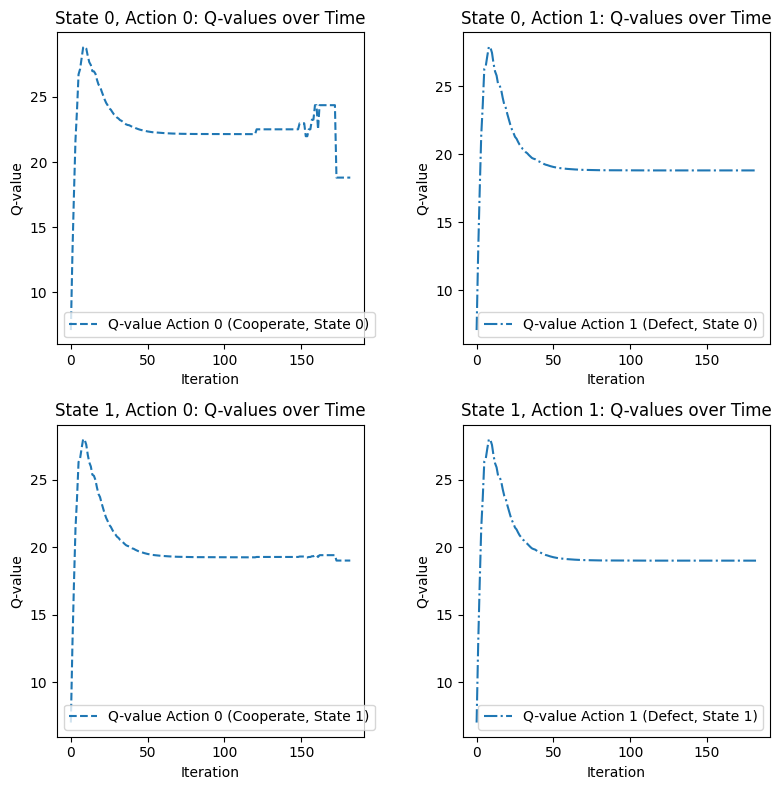

Cooperations: 498, Defections: 1075


In [20]:
# Initialize the solver with GrimTrigger_QValues
strategy = GrimTrigger_QValues()
solver = PrisonersDilemmaSolver(
    strategy=strategy,
    e_initial=0.1,
    lambda_val=0.1,
    alpha=0.1,
    delta=delta_value,
    K=500,
    M=10,
    e_decay=1,
    random_uniform=True,
    verbose=True
)

# Run the solver
cooperations, defections, q1_history, mean_q_values, grim_trigger_count_dict = solver.run()

# Check results
print(f"Cooperations: {cooperations}, Defections: {defections}")


In [21]:
pd.Series(grim_trigger_count_dict)

0    153
1      0
2      0
3      0
4    165
5      0
6      0
7      0
8    156
9      0
dtype: int64

In [3]:
#create theoretical qvalues functions for different values of delta and epsilon

## Multiple Random Seed

In [ ]:
seeds = random.sample(range(1, 10000), 10)

all_cooperations = []
all_defections = []

for seed in seeds:
    random.seed(seed)
    strategy = GrimTrigger_QValues()  # Or use TitForTat()
    solver = PrisonersDilemmaSolver(strategy, e_initial=epsilon_value, 
                                    lambda_val=0.1, 
                                    alpha=0.05, 
                                    delta=0.9, 
                                    K=100, 
                                    M=10, 
                                    e_decay=0.95, 
                                    verbose=False, plotting = False)
    
    cooperations, defections, q = solver.run()
    all_cooperations.append(cooperations)
    all_defections.append(defections)

all_cooperations = np.array(all_cooperations)
all_defections = np.array(all_defections)

mean_cooperations = np.mean(all_cooperations)
mean_defections = np.mean(all_defections)

print(f"Mean cooperations: {mean_cooperations}")
print(f"Mean defections: {mean_defections}")


Number of collaborations: 58, Number of defections: 1365
Expected behavior: defect more
Number of collaborations: 149, Number of defections: 1293
Expected behavior: defect more
Number of collaborations: 143, Number of defections: 1344
Expected behavior: defect more
Number of collaborations: 127, Number of defections: 1310
Expected behavior: defect more
Number of collaborations: 132, Number of defections: 1324
Expected behavior: defect more
Number of collaborations: 78, Number of defections: 1345
Expected behavior: defect more
Number of collaborations: 67, Number of defections: 1338
Expected behavior: defect more
Number of collaborations: 59, Number of defections: 1376
Expected behavior: defect more
Number of collaborations: 92, Number of defections: 1277
Expected behavior: defect more
Number of collaborations: 27, Number of defections: 1391
Expected behavior: defect more
Mean cooperations: 93.2
Mean defections: 1336.3


## Critical Value of delta

In [2]:
def analyze_critical_delta(strategy, e_initial, lambda_val, alpha, delta_range, K, M, e_decay, random_uniform=True):
    """
    Analyzes the critical value of delta for which the agent begins cooperating against the Grim Trigger strategy.
    
    Parameters:
        strategy: The opponent strategy (e.g., GrimTrigger).
        e_initial: Initial exploration rate for Q-learning.
        lambda_val: Eligibility decay parameter.
        alpha: Learning rate for Q-learning.
        delta_range: Tuple specifying the range of delta (min, max, step).
        K: Number of iterations per episode.
        M: Number of episodes to train.
        e_decay: Decay rate for exploration rate.
        random_uniform: Whether to initialize Q-values randomly.
    
    Returns:
        A plot of cooperation ratio vs. delta.
    """
    deltas = np.arange(delta_range[0], delta_range[1], delta_range[2])
    cooperation_ratios = []

    for delta in deltas:
        print(f"Running for delta = {delta:.2f}...")  # Verbose output to track progress
        # Initialize the solver for the given delta
        solver = PrisonersDilemmaSolver(
            strategy=strategy,
            e_initial=e_initial,
            lambda_val=lambda_val,
            alpha=alpha,
            delta=delta,
            K=K,
            M=M,
            e_decay=e_decay,
            random_uniform=random_uniform,
            verbose=False,
            plotting=False  # Suppress plotting for individual runs
        )
        # Run the solver and collect results
        cooperations, defections, _, _ = solver.run()

        # Calculate cooperation ratio
        total_actions = cooperations + defections
        cooperation_ratio = cooperations / total_actions if total_actions > 0 else 0
        cooperation_ratios.append(cooperation_ratio)

    # Plot the cooperation ratio as a function of delta
    plt.figure(figsize=(10, 6))
    plt.plot(deltas, cooperation_ratios, marker='o', linestyle='-', label="Cooperation Ratio")
    plt.axhline(y=0.5, color='r', linestyle='--', label="50% Cooperation Threshold")
    plt.xlabel("Delta (Discount Factor)")
    plt.ylabel("Cooperation Ratio")
    plt.title("Cooperation Ratio vs. Delta in Prisoner's Dilemma")
    plt.legend()
    plt.grid()
    plt.show()

    # Return raw data for further analysis if needed
    return deltas, cooperation_ratios


In [3]:
# Define parameters for the experiment
strategy = GrimTrigger_QValues()
e_initial = 0.1
lambda_val = 0.1
alpha = 0.1
delta_range =  (0.85, 1, 0.01)# Analyze delta from 0.5 to 1.0 in steps of 0.01
K = 500 # Number of iterations per episode
M = 1  # Number of episodes
e_decay = 1  # Decay rate for exploration
random_uniform = False  # Initialize Q-values randomly

# Run the analysis
deltas, cooperation_ratios = analyze_critical_delta(
    strategy=strategy,
    e_initial=e_initial,
    lambda_val=lambda_val,
    alpha=alpha,
    delta_range=delta_range,
    K=K,
    M=M,
    e_decay=e_decay,
    random_uniform=random_uniform
)


Running for delta = 0.85...
Number of collaborations: 0, Number of defections: 123
Expected behavior: defect more
Running for delta = 0.86...
Number of collaborations: 0, Number of defections: 115
Expected behavior: defect more
Running for delta = 0.87...
Number of collaborations: 0, Number of defections: 117
Expected behavior: defect more
Running for delta = 0.88...


KeyboardInterrupt: 

## Detect Grim Trigger Learned

In [19]:
# Helper function to detect Grim Trigger for a given state
def detect_grim_trigger_state(q_cooperate, q_defect):
    grim_trigger_learned = False
    grim_trigger_count = 0

    for i in range(len(q_cooperate)):
        if q_defect[i] >= q_cooperate[i]:  # Defection dominates
            if not grim_trigger_learned:  # Transition detected
                grim_trigger_learned = True
                grim_trigger_count += 1
        else:
            grim_trigger_learned = False  # Reset if cooperation dominates again

    return grim_trigger_count

In [20]:
def detect_grim_trigger_from_dataframe(df):
    """
    Detects how many times Grim Trigger was learned based on Q1 and Q2 values.
    
    Args:
    df (pd.DataFrame): DataFrame with columns Q1 (cooperate, state 0) and Q2 (defect, state 0).

    Returns:
    int: Number of times Grim Trigger was learned.
    """
    q1 = df['Q1'].values
    q2 = df['Q2'].values
    q3 = df['Q3'].values
    q4 = df['Q4'].values

    
    total_grim_trigger_count = 0
    
    for i in range(len(q1)):
        # Count Grim Trigger for both states
        state_0_count = detect_grim_trigger_state(q1, q2)
        state_1_count = detect_grim_trigger_state(q3, q4)

        # Accumulate counts
        total_grim_trigger_count += state_0_count + state_1_count# Count this sample as having learned Grim Trigger

    return total_grim_trigger_count

Final Q-values for Player 1:
[[6.35826716 1.70999745]
 [2.70999599 1.90999719]]
Final Q-values for Player 1 tell us that the player is Collaborating
Number of collaborations: 137, Number of defections: 0
Expected behavior: collaborate more


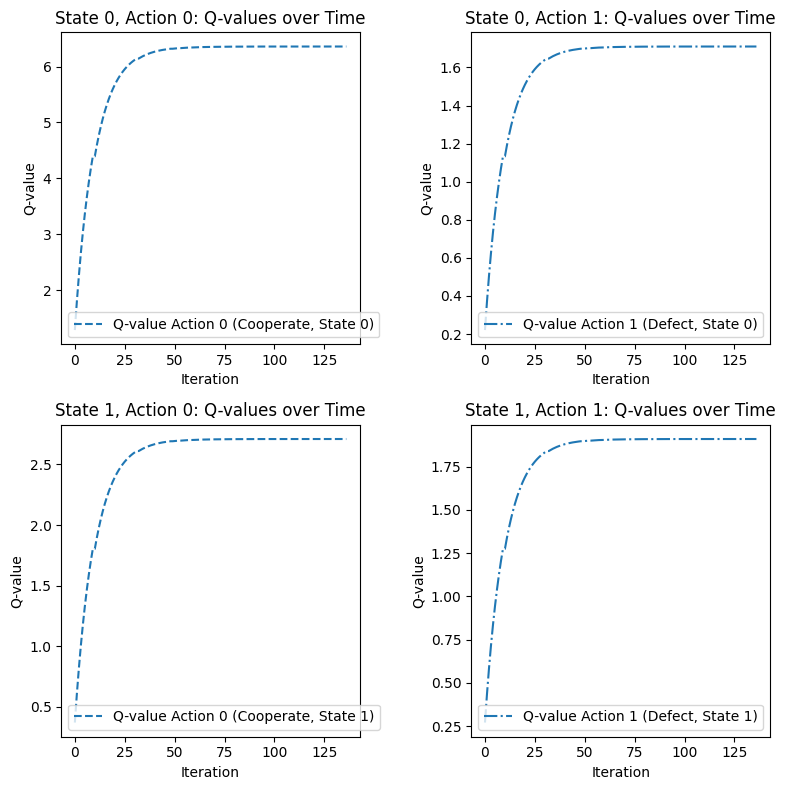

In [27]:
strategy = GrimTrigger_QValues()
solver = PrisonersDilemmaSolver(
    strategy=strategy,
    e_initial=0.1,
    lambda_val=0.1,
    alpha=0.1,
    delta=0.9,
    K=500,
    M=1,
    e_decay=1,
    verbose=True
)

# Run the solver
cooperations, defections, q1_history, mean_q_values = solver.run()


In [ ]:
def plot_q_value_progression(q1_progression):
    iterations = len(q1_progression)
    q1_progression = np.array(q1_progression)  # Shape: (iterations, A, S)

    fig, ax = plt.subplots(figsize=(8, 6))

    # Plot Q-values over iterations
    for i in range(q1_progression.shape[1]):  # Loop over actions
        for j in range(q1_progression.shape[2]):  # Loop over states
            ax.plot(range(iterations), q1_progression[:, i, j], label=f"$Q_{{{i}{j}}}$")

    # Add theoretical Q-values as horizontal lines for reference
    theoretical_q_values = {
        "Q00": 1,
        "Q01": 0.5,
        "Q10": 0.4,
        "Q11": 0.4
    }
    for key, value in theoretical_q_values.items():
        ax.axhline(value, linestyle="--", label=f"Theoretical {key}")

    ax.set_xlabel("Iteration")
    ax.set_ylabel("Q-value")
    ax.set_title("Q-value Convergence Over Iterations")
    ax.legend()
    plt.tight_layout()
    plt.show()

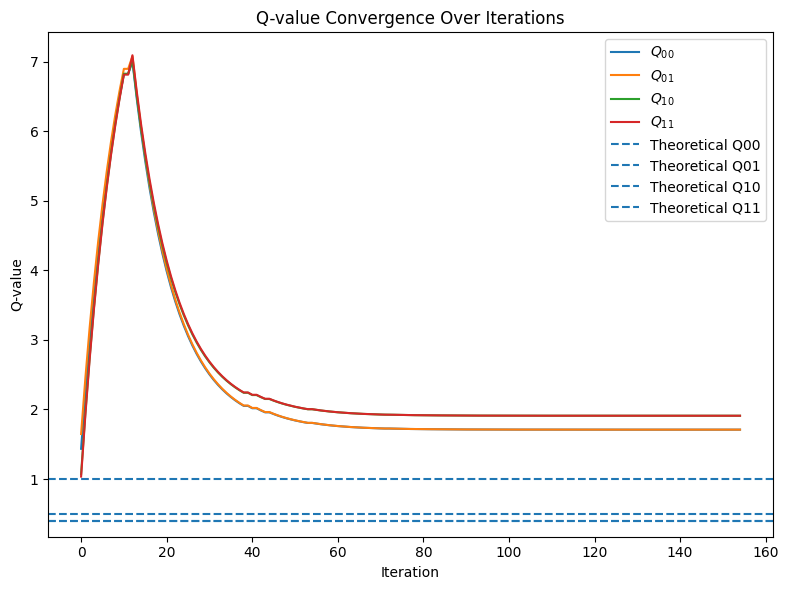

In [26]:
plot_q_value_progression(q1_history)